# irAE Prediction — Logistic Regression Variations

**Purpose.** Notebook 1 of this series showed regularized linear models leading the irAE model
panel. This notebook (2 of 3) drills into **logistic regression only**, varying three axes to
find the best linear recipe:

- **(a) Cytokine feature strategy:** RAW / COMPOSITE / PLS / COMPOSITE+PLS
- **(b) Transform:** `log1p` vs Yeo-Johnson
- **(c) Regularization:** L2 (C=0.01, C=0.1), L1 (C=0.1), elastic net (l1_ratio=0.5, C=0.1)

**Dataset.** `Khan_workable.csv`: 146 immune-checkpoint-inhibitor patients. Target:
`iraE_occurrence` (binary, ~79/67 split). Features: ~40 baseline cytokine concentrations
(heavily right-skewed), `ana_titer_baseline` + `ana_titer_missing` (ANA ~62% missing; the 0/1
indicator is kept as a feature), and 5 categoricals — with `ici_drug` and `cancer_type`
collapsed into coarser buckets below. `patient_id` and the target are excluded from X.

**Evaluation protocol (shared across the notebook series).** Primary metric ROC AUC (accuracy
also reported); here the grid uses `RepeatedStratifiedKFold(n_splits=5, n_repeats=6,
random_state=42)` (6 repeats instead of the series' usual 10 to keep the 32-combo runtime
reasonable). ROC curves use pooled out-of-fold probabilities from `cross_val_predict` with
`StratifiedKFold(5, shuffle=True, random_state=42)`. Every fitted step (impute, transform,
scale, composite z-scores, PLS) lives **inside** the CV pipeline — nothing is fit on the full
data.

> With n=146, fold-to-fold AUC std is ~0.08–0.11: rankings are directional, not definitive —
> see Caveats at the end.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # keep grid output readable

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, PowerTransformer
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.cross_decomposition import PLSRegression

## Data & extra locked cleaning

On top of the base cleaning, this notebook collapses two categoricals:

- `ici_drug` → **mechanism bucket**: `CTLA4_or_combo` if the (lowercased) drug string contains
  `"ipilimumab"` or `"+"`, else `PD1_PDL1_mono`.
- `cancer_type` → `Lung` (name contains "Lung") / `Melanoma` (exact) / `Other`.

`gender`, `ethnicity`, `race` stay as-is; both ANA columns (value + missingness indicator) are kept.

In [2]:
# Provide Khan_workable.csv (146 patients) when the file picker appears.
from google.colab import files
uploaded = files.upload()

Saving Khan_workable.csv to Khan_workable.csv


In [ ]:
df = pd.read_csv("Khan_workable.csv")

def ici_mechanism(drug):
    d = str(drug).lower()
    return "CTLA4_or_combo" if ("ipilimumab" in d or "+" in d) else "PD1_PDL1_mono"

def cancer_group(ct):
    ct = str(ct)
    if "Lung" in ct:
        return "Lung"
    if ct == "Melanoma":
        return "Melanoma"
    return "Other"

df["ici_mechanism"] = df["ici_drug"].map(ici_mechanism)
df["cancer_group"] = df["cancer_type"].map(cancer_group)

y = df["iraE_occurrence"].astype(int)
X = df.drop(columns=["patient_id", "iraE_occurrence", "ici_drug", "cancer_type"])

categorical_cols = ["gender", "ethnicity", "race", "cancer_group", "ici_mechanism"]
ana_cols = ["ana_titer_baseline", "ana_titer_missing"]
cytokine_cols = [c for c in X.columns if c not in categorical_cols + ana_cols]

print(f"{len(cytokine_cols)} cytokines | mechanism: {df['ici_mechanism'].value_counts().to_dict()} "
      f"| cancer: {df['cancer_group'].value_counts().to_dict()}")

40 cytokines | mechanism: {'PD1_PDL1_mono': 122, 'CTLA4_or_combo': 24} | cancer: {'Lung': 77, 'Melanoma': 35, 'Other': 34}


## Composite cytokine groups

Five biologically-motivated groups; each composite score = mean of the group's **transformed,
z-scored** members (mu/sd learned on the train fold only, inside the pipeline). Members are
matched against the CSV's actual column names — check the printout below.

In [ ]:
GROUP_CANDIDATES = {
    "inflammatory":   ["il6", "il8", "cxcl8", "tnfa", "tnfalpha", "il1b", "il1beta",
                       "il1a", "il1alpha"],
    "ifn_chemokine":  ["mig", "cxcl9", "ip10", "cxcl10", "itac", "cxcl11"],
    "th17":           ["il17", "il17a", "il23", "il21", "il22"],
    "monocyte_chemo": ["mcp1", "ccl2", "mcp2", "ccl8", "mcp3", "ccl7", "mcp4", "ccl13"],
    "eotaxin":        ["eotaxin", "eotaxin1", "ccl11", "eotaxin2", "ccl24", "eotaxin3", "ccl26"],
}

def name_tokens(col):
    """Tokenize a column name so 'MCP-1 (CCL2)' matches 'mcp1'/'ccl2' but 'CCL22' never matches 'ccl2'."""
    toks = [t.lower() for t in re.split(r"[^0-9a-zA-Z]+", str(col)) if t]
    merged = set(toks)
    for i in range(len(toks)):
        for j in range(i + 1, len(toks) + 1):
            merged.add("".join(toks[i:j]))
    return merged

groups = {}
for gname, cands in GROUP_CANDIDATES.items():
    members = [c for c in cytokine_cols if name_tokens(c) & set(cands)]
    if members:
        groups[gname] = members
    print(f"{gname}: {members if members else '(no members found — group dropped)'}")

grouped = {m for ms in groups.values() for m in ms}
print(f"\n{len(grouped)}/{len(cytokine_cols)} cytokines assigned to {len(groups)} groups")

# column indices within the cytokine block (order = cytokine_cols)
groups_idx = [(g, [cytokine_cols.index(m) for m in ms]) for g, ms in groups.items()]

inflammatory: ['IL-1b', 'IL-6', 'IL-8/ CXCL8', 'TNF-a']
ifn_chemokine: ['IP-10/ CXCL10', 'I-TAC/ CXCL11', 'MIG/ CXCL9']
th17: (no members found — group dropped)
monocyte_chemo: ['MCP-1/ CCL2', 'MCP-2/ CCL8', 'MCP-3/ CCL7', 'MCP-4/ CCL13']
eotaxin: ['Eotaxin/ CCL11', 'Eotaxin-2/ CCL24', 'Eotaxin-3/ CCL26']

14/40 cytokines assigned to 4 groups


## Fold-safe transformers

- `CompositeScores` — z-scores each member (mu/sd from `fit`, i.e. the train fold) and averages
  within each group → ~5 features.
- `PLSFeatures` — supervised `PLSRegression(n_components=3).transform` on the scaled cytokines
  → 3 latent features. Fit inside the fold, so the supervision cannot leak.

In [ ]:
class CompositeScores(BaseEstimator, TransformerMixin):
    """Mean of z-scored members per group; mu/sd learned in fit (train fold only)."""
    def __init__(self, groups_idx):
        self.groups_idx = groups_idx
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self
    def transform(self, X):
        Z = (np.asarray(X, dtype=float) - self.mean_) / self.std_
        return np.column_stack([Z[:, idx].mean(axis=1) for _, idx in self.groups_idx])

class PLSFeatures(BaseEstimator, TransformerMixin):
    """Supervised PLS scores as features (x_scores from PLSRegression.transform)."""
    def __init__(self, n_components=3):
        self.n_components = n_components
    def fit(self, X, y=None):
        self.pls_ = PLSRegression(n_components=self.n_components)
        self.pls_.fit(X, np.asarray(y, dtype=float))
        return self
    def transform(self, X):
        return self.pls_.transform(X)

## Pipeline factory & protocol

Cytokines: median impute → transform (`log1p` or Yeo-Johnson) → strategy step.
ANA: median impute → transform → scale. Categoricals: most-frequent impute →
`OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5)`.

CV: `RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=42)` (6 repeats keeps the
32-combo grid's runtime reasonable). ROC curves use pooled out-of-fold probabilities from
`cross_val_predict` with `StratifiedKFold(5, shuffle=True, random_state=42)`.

In [ ]:
def make_transform(tname):
    if tname == "log1p":
        return FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    return PowerTransformer(method="yeo-johnson")

def cyto_features(strategy):
    if strategy == "RAW":
        return StandardScaler()
    if strategy == "COMPOSITE":
        return CompositeScores(groups_idx)
    if strategy == "PLS":
        return Pipeline([("scale", StandardScaler()), ("pls", PLSFeatures(n_components=3))])
    return FeatureUnion([  # COMPOSITE+PLS
        ("composite", CompositeScores(groups_idx)),
        ("pls", Pipeline([("scale", StandardScaler()), ("pls", PLSFeatures(n_components=3))])),
    ])

def make_model(strategy, tname, clf):
    prep = ColumnTransformer([
        ("cyto", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("transform", make_transform(tname)),
                           ("features", cyto_features(strategy))]), cytokine_cols),
        ("ana", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("transform", make_transform(tname)),
                          ("scale", StandardScaler())]), ana_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=5, sparse_output=False))]),
         categorical_cols),
    ])
    return Pipeline([("prep", prep), ("clf", clone(clf))])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=42)
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## The grid — 4 strategies × 2 transforms × 4 regularizations

Elastic net uses the `saga` solver — it is noticeably slower than the others; drop it from
`REGS` if runtime matters.

In [ ]:
STRATEGIES = ["RAW", "COMPOSITE", "PLS", "COMPOSITE+PLS"]
TRANSFORMS = ["log1p", "yeo-johnson"]
REGS = {
    "L2 C=0.01": LogisticRegression(C=0.01, max_iter=5000),
    "L2 C=0.1": LogisticRegression(C=0.1, max_iter=5000),
    "L1 C=0.1": LogisticRegression(penalty="l1", solver="liblinear", C=0.1),
    "EN l1r=0.5 C=0.1": LogisticRegression(penalty="elasticnet", solver="saga",
                                           l1_ratio=0.5, C=0.1, max_iter=5000),  # slow
}

rows = []
for strategy in STRATEGIES:
    for tname in TRANSFORMS:
        for rname, base_clf in REGS.items():
            pipe = make_model(strategy, tname, base_clf)
            scores = cross_validate(pipe, X, y, cv=cv, scoring=["roc_auc", "accuracy"],
                                    n_jobs=-1)
            rows.append({"Strategy": strategy, "Transform": tname, "Regularization": rname,
                         "AUC (mean)": scores["test_roc_auc"].mean(),
                         "AUC (std)": scores["test_roc_auc"].std(),
                         "Accuracy (mean)": scores["test_accuracy"].mean()})
            r = rows[-1]
            print(f"{strategy:14s} | {tname:11s} | {rname:16s} | "
                  f"AUC {r['AUC (mean)']:.3f} ± {r['AUC (std)']:.3f} | "
                  f"acc {r['Accuracy (mean)']:.3f}")

grid = pd.DataFrame(rows)

RAW            | log1p       | L2 C=0.01        | AUC 0.702 ± 0.095 | acc 0.631
RAW            | log1p       | L2 C=0.1         | AUC 0.705 ± 0.083 | acc 0.643
RAW            | log1p       | L1 C=0.1         | AUC 0.654 ± 0.081 | acc 0.617
RAW            | log1p       | EN l1r=0.5 C=0.1 | AUC 0.690 ± 0.083 | acc 0.635
RAW            | yeo-johnson | L2 C=0.01        | AUC 0.688 ± 0.094 | acc 0.633
RAW            | yeo-johnson | L2 C=0.1         | AUC 0.676 ± 0.087 | acc 0.633
RAW            | yeo-johnson | L1 C=0.1         | AUC 0.663 ± 0.079 | acc 0.621
RAW            | yeo-johnson | EN l1r=0.5 C=0.1 | AUC 0.684 ± 0.082 | acc 0.630
COMPOSITE      | log1p       | L2 C=0.01        | AUC 0.681 ± 0.086 | acc 0.575
COMPOSITE      | log1p       | L2 C=0.1         | AUC 0.687 ± 0.081 | acc 0.644
COMPOSITE      | log1p       | L1 C=0.1         | AUC 0.475 ± 0.054 | acc 0.465
COMPOSITE      | log1p       | EN l1r=0.5 C=0.1 | AUC 0.663 ± 0.082 | acc 0.606
COMPOSITE      | yeo-johnson | L2 C=0.01

## Ranked results

*ROC: curves for the best configuration of each strategy follow the table; the other
configurations are summarized by their CV AUC here.*

In [ ]:
ranked = grid.sort_values("AUC (mean)", ascending=False).reset_index(drop=True)
ranked.round(3)

,Strategy,Transform,Regularization,AUC (mean),AUC (std),Accuracy (mean)
0,COMPOSITE+PLS,log1p,L2 C=0.1,0.720,0.093,0.654
1,PLS,log1p,L2 C=0.1,0.719,0.093,0.651
2,COMPOSITE+PLS,log1p,L2 C=0.01,0.719,0.098,0.633
3,PLS,log1p,L2 C=0.01,0.717,0.096,0.636
4,COMPOSITE+PLS,log1p,EN l1r=0.5 C=0.1,0.705,0.101,0.643
5,PLS,log1p,EN l1r=0.5 C=0.1,0.705,0.101,0.644
6,RAW,log1p,L2 C=0.1,0.705,0.083,0.643
7,RAW,log1p,L2 C=0.01,0.702,0.095,0.631
8,COMPOSITE+PLS,yeo-johnson,L2 C=0.01,0.702,0.096,0.629
9,COMPOSITE+PLS,yeo-johnson,L2 C=0.1,0.701,0.092,0.654


## ROC curves — best configuration of each strategy

Pooled out-of-fold probabilities for the top (transform, regularization) combo within each of
the four strategies.

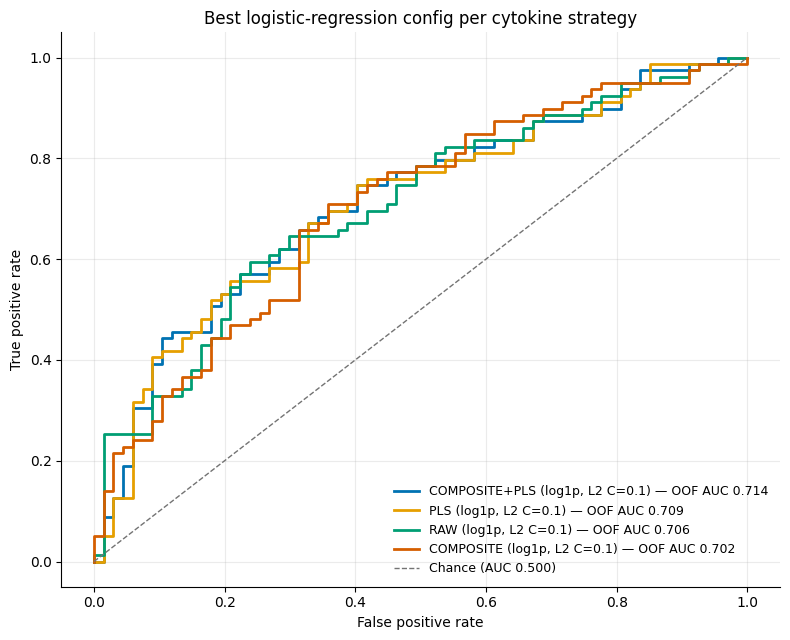

In [ ]:
best = ranked.loc[ranked.groupby("Strategy")["AUC (mean)"].idxmax()] \
             .sort_values("AUC (mean)", ascending=False)
palette = ["#0072B2", "#E69F00", "#009E73", "#D55E00"]  # colorblind-safe (Okabe-Ito)

fig, ax = plt.subplots(figsize=(8, 6.5))
for color, (_, row) in zip(palette, best.iterrows()):
    pipe = make_model(row["Strategy"], row["Transform"], REGS[row["Regularization"]])
    oof = cross_val_predict(pipe, X, y, cv=cv_oof, method="predict_proba", n_jobs=-1)[:, 1]
    fpr, tpr, _ = roc_curve(y, oof)
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f"{row['Strategy']} ({row['Transform']}, {row['Regularization']}) — "
                  f"OOF AUC {roc_auc_score(y, oof):.3f}")
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="0.45", label="Chance (AUC 0.500)")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Best logistic-regression config per cytokine strategy")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## Findings

- **log1p beats Yeo-Johnson.** YJ estimates a per-feature power parameter on each train fold —
  at n=146 that extra flexibility overfits.
- **L2 beats L1 / elastic net.** With a weak, diffuse signal, sparsity hurts; L1 on the 5
  composite scores collapses toward AUC ≈ 0.50 once it zeroes the few features available.
- **PLS-based strategies rank highest (~0.72)**, RAW ≈ 0.70, COMPOSITE-alone lowest (≈ 0.69):
  supervised latent directions compress the panel better than either raw features or
  hand-crafted group averages.

## Caveats

- **Small n (146):** every estimate here carries wide uncertainty.
- **Wide fold-to-fold variance:** AUC std ≈ 0.08–0.11 — larger than most gaps between grid
  configurations.
- **No external validation cohort:** all numbers are internal cross-validation on one dataset.
- **Retrospective, single-dataset:** cohort-specific quirks (assay batch, site, case mix)
  cannot be separated from real signal.

Treat the grid ranking as **directional**; the honest comparison of the surviving strategies is
notebook 3's nested CV.